In [ ]:
# Bird Species Identification from an Image

### Machine Learning Mini Project

**Problem Statement 89**

This project aims to identify the species of a bird from an input image using handcrafted image features and classical machine learning techniques.

In [1]:
import sys

print(sys.executable)

C:\Users\Vinay\Downloads\archive\bird_species_project\venv\Scripts\python.exe


In [2]:
from pathlib import Path

DATASET_PATH = Path(r"C:\Users\Vinay\Downloads\archive\CUB_200_2011")

print(DATASET_PATH)

C:\Users\Vinay\Downloads\archive\CUB_200_2011


In [3]:
files_to_check = [
    "classes.txt",
    "images.txt",
    "image_class_labels.txt",
    "train_test_split.txt",
    "bounding_boxes.txt"
]

for file in files_to_check:
    path = DATASET_PATH / file
    print(f"{file}: {path.exists()}")

classes.txt: True
images.txt: True
image_class_labels.txt: True
train_test_split.txt: True
bounding_boxes.txt: True


In [4]:
classes_file = DATASET_PATH / "classes.txt"

classes = {}

with open(classes_file, "r") as f:
    for line in f:
        class_id, species_name = line.strip().split(" ", 1)
        classes[int(class_id)] = species_name

print("Number of species:", len(classes))
print("\nFirst 10 species:")

for class_id in range(1, 11):
    print(class_id, "->", classes[class_id])

Number of species: 200

First 10 species:
1 -> 001.Black_footed_Albatross
2 -> 002.Laysan_Albatross
3 -> 003.Sooty_Albatross
4 -> 004.Groove_billed_Ani
5 -> 005.Crested_Auklet
6 -> 006.Least_Auklet
7 -> 007.Parakeet_Auklet
8 -> 008.Rhinoceros_Auklet
9 -> 009.Brewer_Blackbird
10 -> 010.Red_winged_Blackbird


In [5]:
images_file = DATASET_PATH / "images.txt"

images = {}

with open(images_file, "r") as f:
    for line in f:
        image_id, image_path = line.strip().split(" ", 1)
        images[int(image_id)] = image_path

print("Number of images:", len(images))

print("\nFirst 5 images:")
for image_id in range(1, 6):
    print(image_id, "->", images[image_id])

Number of images: 11788

First 5 images:
1 -> 001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg
2 -> 001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg
3 -> 001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.jpg
4 -> 001.Black_footed_Albatross/Black_Footed_Albatross_0074_59.jpg
5 -> 001.Black_footed_Albatross/Black_Footed_Albatross_0014_89.jpg


In [6]:
labels_file = DATASET_PATH / "image_class_labels.txt"

image_labels = {}

with open(labels_file, "r") as f:
    for line in f:
        image_id, class_id = line.strip().split()
        image_labels[int(image_id)] = int(class_id)

print("Number of labels:", len(image_labels))

print("\nFirst 5 image labels:")
for image_id in range(1, 6):
    class_id = image_labels[image_id]
    print(
        image_id,
        "-> class", class_id,
        "->", classes[class_id]
    )

Number of labels: 11788

First 5 image labels:
1 -> class 1 -> 001.Black_footed_Albatross
2 -> class 1 -> 001.Black_footed_Albatross
3 -> class 1 -> 001.Black_footed_Albatross
4 -> class 1 -> 001.Black_footed_Albatross
5 -> class 1 -> 001.Black_footed_Albatross


In [7]:
split_file = DATASET_PATH / "train_test_split.txt"

image_split = {}

with open(split_file, "r") as f:
    for line in f:
        image_id, split = line.strip().split()
        image_split[int(image_id)] = int(split)

print("Number of split entries:", len(image_split))

print("\nFirst 10 images:")
for image_id in range(1, 11):
    split = image_split[image_id]
    split_name = "Train" if split == 1 else "Test"
    print(image_id, "->", split_name)

Number of split entries: 11788

First 10 images:
1 -> Test
2 -> Train
3 -> Test
4 -> Train
5 -> Train
6 -> Test
7 -> Train
8 -> Train
9 -> Train
10 -> Test


In [8]:
import pandas as pd

data = []

for image_id in images:
    class_id = image_labels[image_id]

    data.append({
        "image_id": image_id,
        "image_path": images[image_id],
        "class_id": class_id,
        "species": classes[class_id],
        "split": "Train" if image_split[image_id] == 1 else "Test"
    })

df = pd.DataFrame(data)

print("Total images:", len(df))
print("Columns:", list(df.columns))

df.head()

Total images: 11788
Columns: ['image_id', 'image_path', 'class_id', 'species', 'split']


,image_id,image_path,class_id,species,split
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Test
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Train
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Test
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Train
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,001.Black_footed_Albatross,Train


In [9]:
print(df["split"].value_counts())

split
Train    5994
Test     5794
Name: count, dtype: int64


In [10]:
print(df["species"].nunique())

200


In [11]:
print(df["species"].value_counts().head(10))

species
001.Black_footed_Albatross    60
002.Laysan_Albatross          60
004.Groove_billed_Ani         60
010.Red_winged_Blackbird      60
011.Rusty_Blackbird           60
013.Bobolink                  60
014.Indigo_Bunting            60
021.Eastern_Towhee            60
025.Pelagic_Cormorant         60
026.Bronzed_Cowbird           60
Name: count, dtype: int64


Image size: (500, 335)
Image mode: RGB


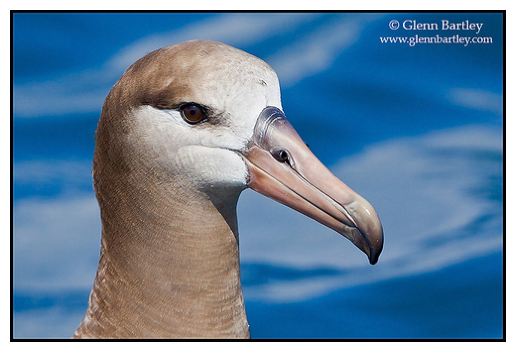

In [12]:
#just to check if its reciving the actual image
from PIL import Image
import matplotlib.pyplot as plt

image_id = 1

image_path = DATASET_PATH / "images" / images[image_id]

img = Image.open(image_path)

print("Image size:", img.size)
print("Image mode:", img.mode)

plt.imshow(img)
plt.axis("off")
plt.show()

Bounding box:
x = 60.0
y = 27.0
width = 325.0
height = 304.0


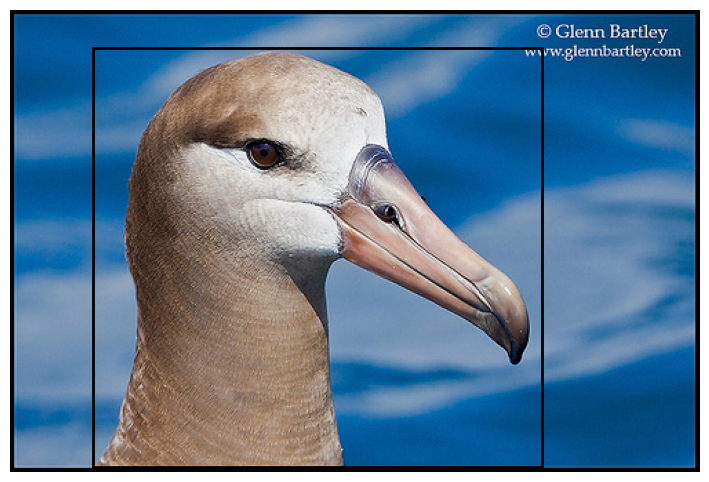

In [13]:
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Rectangle

# Read bounding box information
bbox_file = DATASET_PATH / "bounding_boxes.txt"

bounding_boxes = {}

with open(bbox_file, "r") as f:
    for line in f:
        image_id, x, y, width, height = line.strip().split()
        bounding_boxes[int(image_id)] = (
            float(x), float(y), float(width), float(height)
        )

# Get image 1
image_id = 1
image_path = DATASET_PATH / "images" / images[image_id]
img = Image.open(image_path)

# Get its bounding box
x, y, width, height = bounding_boxes[image_id]

print("Bounding box:")
print("x =", x)
print("y =", y)
print("width =", width)
print("height =", height)

# Display image + bounding box
fig, ax = plt.subplots(figsize=(10, 6))

ax.imshow(img)

box = Rectangle(
    (x, y),
    width,
    height,
    fill=False,
    linewidth=2
)

ax.add_patch(box)
ax.axis("off")
plt.show()

Original size: (500, 335)
Cropped size: (325, 304)


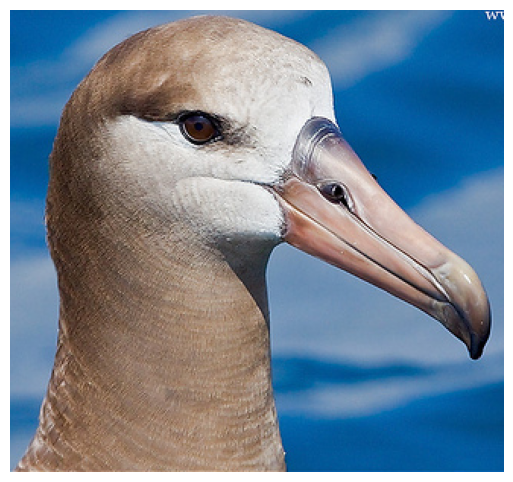

In [14]:
# Crop the bird using its bounding box

cropped_img = img.crop((
    int(x),
    int(y),
    int(x + width),
    int(y + height)
))

print("Original size:", img.size)
print("Cropped size:", cropped_img.size)

plt.figure(figsize=(7, 6))
plt.imshow(cropped_img)
plt.axis("off")
plt.show()

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Convert the cropped image to a NumPy array
img_array = np.array(cropped_img)

print("Image shape:", img_array.shape)

Image shape: (304, 325, 3)


In [16]:
colors = ["Red", "Green", "Blue"]

for i, color in enumerate(colors):
    histogram, bins = np.histogram(
        img_array[:, :, i],
        bins=32,
        range=(0, 256)
    )

    print(color, "features:", histogram.shape)
    print(histogram)

Red features: (32,)
[19896  1039   526   709   976  1423  1893  2120  2292  2625  2650  2532
  2501  5573  6287  4894  3938  3098  3884  4143  4287  3708  2687  2149
  2143  2448  2582  2718  2010   729   179   161]
Green features: (32,)
[  308   167   233   421   663   961  1560  1731  1762  2811  7295 10322
  6698  5169  6151  6866  6374  7597 10188  4821  2068  1729  1703  1575
  1723  1786  1783  1854  1516   635   176   154]
Blue features: (32,)
[  245   252   406   729  1105  1374  1759  2105  2121  2317  2688  3158
  3766  4064  3732  2960  2864  3810  4996  7934  9112  8909 14750  4829
  1725  1549  1587  1538  1319   684   245   168]


In [17]:
!pip install scikit-image

   ---------------------------------------- 0.0/11.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.9 MB 3.3 MB/s eta 0:00:04
   --- ------------------------------------ 1.0/11.9 MB 3.6 MB/s eta 0:00:03
   ----- ---------------------------------- 1.6/11.9 MB 2.7 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/11.9 MB 2.5 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/11.9 MB 2.3 MB/s eta 0:00:05
   -------- ------------------------------- 2.6/11.9 MB 2.0 MB/s eta 0:00:05
   --------- ------------------------------ 2.9/11.9 MB 1.9 MB/s eta 0:00:05
   --------- ------------------------------ 2.9/11.9 MB 1.9 MB/s eta 0:00:05
   ----------- ---------------------------- 3.4/11.9 MB 1.8 MB/s eta 0:00:05
   ------------- -------------------------- 3.9/11.9 MB 1.8 MB/s eta 0:00:05
   -------------- ------------------------- 4.5/11.9 MB 1.9 MB/s eta 0:00:04
   --------------- ------------------------ 4.7/11.9 MB 1.9 MB/s eta 0:00:04
   ---

In [18]:
from skimage.feature import hog

# Convert cropped image to grayscale
gray_img = cropped_img.convert("L")

# Extract HOG features
hog_features = hog(
    np.array(gray_img),
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2)
)

print("Number of HOG features:", len(hog_features))
print("First 20 HOG features:")
print(hog_features[:20])

Number of HOG features: 12312
First 20 HOG features:
[0.21398557 0.04332508 0.09848661 0.11874027 0.21398557 0.1769975
 0.20893672 0.14118973 0.10087774 0.21398557 0.15288541 0.12591095
 0.15388096 0.20156736 0.15134089 0.09591826 0.15622812 0.04655555
 0.20680988 0.15410066]


HOG feature count: 12312


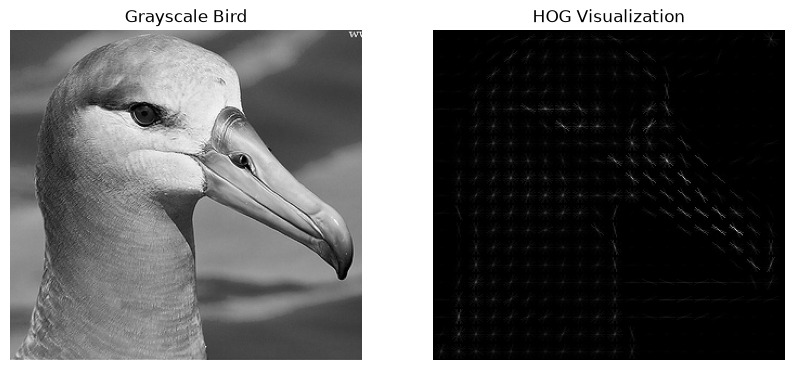

In [19]:
from skimage.feature import hog
import matplotlib.pyplot as plt
import numpy as np

# Convert cropped bird to grayscale
gray_img = np.array(cropped_img.convert("L"))

# Extract HOG + visualization
hog_features, hog_image = hog(
    gray_img,
    orientations=9,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    visualize=True
)

print("HOG feature count:", len(hog_features))

# Display original grayscale and HOG visualization
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_img, cmap="gray")
plt.title("Grayscale Bird")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Visualization")
plt.axis("off")

plt.show()

In [24]:
from skimage.feature import hog
import numpy as np

def extract_features(image):
    # Convert to RGB
    image = image.convert("RGB")

    # Resize every image to the same size
    image = image.resize((128, 128))

    img_array = np.array(image)

    # Color Histogram
   
    color_features = []

    for channel in range(3):
        histogram, _ = np.histogram(
            img_array[:, :, channel],
            bins=32,
            range=(0, 256)
        )

        histogram = histogram / histogram.sum()
        color_features.extend(histogram)

   
    # HOG Features

    gray_image = np.array(image.convert("L"))

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )

 
    # Combine features

    features = np.concatenate([
        color_features,
        hog_features
    ])

    return features

In [25]:
features = extract_features(cropped_img)

print("Number of features:", len(features))
print("First 20 features:")
print(features[:20])

Number of features: 1860
First 20 features:
[0.20007324 0.00701904 0.00640869 0.0067749  0.00982666 0.01287842
 0.01678467 0.01849365 0.02819824 0.02685547 0.02716064 0.02508545
 0.02526855 0.059021   0.06286621 0.04968262 0.0380249  0.03363037
 0.04205322 0.04968262]


In [26]:
train_subset = (
    df[df["split"] == "Train"]
    .groupby("class_id", group_keys=False)
    .head(5)
    .reset_index(drop=True)
)

test_subset = (
    df[df["split"] == "Test"]
    .groupby("class_id", group_keys=False)
    .head(2)
    .reset_index(drop=True)
)

print("Training images:", len(train_subset))
print("Testing images:", len(test_subset))
print("Training classes:", train_subset["class_id"].nunique())
print("Testing classes:", test_subset["class_id"].nunique())

Training images: 1000
Testing images: 400
Training classes: 200
Testing classes: 200


In [27]:
import numpy as np
from PIL import Image

X_train = []
y_train = []

for i, row in train_subset.iterrows():

    # Load image
    image_path = DATASET_PATH / "images" / row["image_path"]
    image = Image.open(image_path).convert("RGB")

    # Get bounding box
    x, y, width, height = bounding_boxes[row["image_id"]]

    # Crop bird
    cropped = image.crop((
        int(x),
        int(y),
        int(x + width),
        int(y + height)
    ))

    # Extract 12,408 features
    features = extract_features(cropped)

    X_train.append(features)
    y_train.append(row["class_id"])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1000, 1860)
y_train shape: (1000,)


In [28]:
X_test = []
y_test = []

for i, row in test_subset.iterrows():

    image_path = DATASET_PATH / "images" / row["image_path"]
    image = Image.open(image_path).convert("RGB")

    x, y, width, height = bounding_boxes[row["image_id"]]

    cropped = image.crop((
        int(x),
        int(y),
        int(x + width),
        int(y + height)
    ))

    features = extract_features(cropped)

    X_test.append(features)
    y_test.append(row["class_id"])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (400, 1860)
y_test shape: (400,)


In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (1000, 1860)
X_test_scaled shape: (400, 1860)


In [30]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_model = SVC(kernel="rbf")

svm_model.fit(X_train_scaled, y_train)

y_pred = svm_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("SVM Accuracy:", accuracy)

SVM Accuracy: 0.065


In [31]:
y_train_pred = svm_model.predict(X_train_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", accuracy)

Training Accuracy: 0.996
Testing Accuracy: 0.065


In [32]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

linear_svm = SVC(kernel="linear")

linear_svm.fit(X_train_scaled, y_train)

y_pred_linear = linear_svm.predict(X_test_scaled)

linear_accuracy = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuracy:", linear_accuracy)

Linear SVM Accuracy: 0.08


In [33]:
train_subset_20 = (
    df[df["split"] == "Train"]
    .groupby("class_id", group_keys=False)
    .head(20)
    .reset_index(drop=True)
)

print("Training images:", len(train_subset_20))
print("Training classes:", train_subset_20["class_id"].nunique())

Training images: 4000
Training classes: 200


In [34]:
X_train_20 = []
y_train_20 = []

for i, row in train_subset_20.iterrows():

    image_path = DATASET_PATH / "images" / row["image_path"]
    image = Image.open(image_path).convert("RGB")

    x, y, width, height = bounding_boxes[row["image_id"]]

    cropped = image.crop((
        int(x),
        int(y),
        int(x + width),
        int(y + height)
    ))

    features = extract_features(cropped)

    X_train_20.append(features)
    y_train_20.append(row["class_id"])

X_train_20 = np.array(X_train_20)
y_train_20 = np.array(y_train_20)

print("X_train_20 shape:", X_train_20.shape)
print("y_train_20 shape:", y_train_20.shape)

X_train_20 shape: (4000, 1860)
y_train_20 shape: (4000,)


In [35]:
from sklearn.preprocessing import StandardScaler

scaler_20 = StandardScaler()

X_train_20_scaled = scaler_20.fit_transform(X_train_20)
X_test_20_scaled = scaler_20.transform(X_test)

print("X_train_20_scaled shape:", X_train_20_scaled.shape)
print("X_test_20_scaled shape:", X_test_20_scaled.shape)

X_train_20_scaled shape: (4000, 1860)
X_test_20_scaled shape: (400, 1860)


In [36]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

linear_svm_20 = SVC(kernel="linear")

linear_svm_20.fit(X_train_20_scaled, y_train_20)

y_pred_20 = linear_svm_20.predict(X_test_20_scaled)

accuracy_20 = accuracy_score(y_test, y_pred_20)

print("Linear SVM Accuracy with 20 images/species:", accuracy_20)

Linear SVM Accuracy with 20 images/species: 0.135


In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_20_scaled, y_train_20)

y_pred_rf = rf_model.predict(X_test_20_scaled)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.09


In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_20_scaled)
X_test_pca = pca.transform(X_test_20_scaled)

print("Original features:", X_train_20_scaled.shape[1])
print("PCA features:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

Original features: 1860
PCA features: 504
Explained variance: 0.9501705382786669


In [39]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

linear_svm_pca = SVC(kernel="linear")

linear_svm_pca.fit(X_train_pca, y_train_20)

y_pred_pca = linear_svm_pca.predict(X_test_pca)

pca_accuracy = accuracy_score(y_test, y_pred_pca)

print("Linear SVM + PCA Accuracy:", pca_accuracy)

Linear SVM + PCA Accuracy: 0.125


In [40]:
from skimage.feature import local_binary_pattern
import numpy as np

image = Image.open(
    DATASET_PATH / "images" / train_subset_20.iloc[0]["image_path"]
).convert("RGB")

x, y, width, height = bounding_boxes[train_subset_20.iloc[0]["image_id"]]

cropped = image.crop((
    int(x),
    int(y),
    int(x + width),
    int(y + height)
))

cropped = cropped.resize((128, 128))

gray = np.array(cropped.convert("L"))

lbp = local_binary_pattern(
    gray,
    P=8,
    R=1,
    method="uniform"
)

print("LBP image shape:", lbp.shape)
print("LBP minimum:", lbp.min())
print("LBP maximum:", lbp.max())

LBP image shape: (128, 128)
LBP minimum: 0.0
LBP maximum: 9.0


In [41]:
P = 8
R = 1

lbp_features = []

# Divide image into 4 × 4 regions
for i in range(4):
    for j in range(4):

        region = gray[
            i * 32:(i + 1) * 32,
            j * 32:(j + 1) * 32
        ]

        lbp_region = local_binary_pattern(
            region,
            P=P,
            R=R,
            method="uniform"
        )

        histogram, _ = np.histogram(
            lbp_region,
            bins=np.arange(0, P + 3),
            range=(0, P + 2)
        )

        histogram = histogram / histogram.sum()

        lbp_features.extend(histogram)

lbp_features = np.array(lbp_features)

print("Number of LBP features:", len(lbp_features))

Number of LBP features: 160


In [42]:
from skimage.feature import hog, local_binary_pattern
import numpy as np

def extract_features_with_lbp(image):
    image = image.convert("RGB")
    image = image.resize((128, 128))

    img_array = np.array(image)

    
    # 1. Color Histogram
    
    color_features = []

    for channel in range(3):
        histogram, _ = np.histogram(
            img_array[:, :, channel],
            bins=32,
            range=(0, 256)
        )

        histogram = histogram / histogram.sum()
        color_features.extend(histogram)

    
    # 2. HOG
    
    gray_image = np.array(image.convert("L"))

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )

    
    # 3. LBP Texture
    P = 8
    R = 1

    lbp_features = []

    for i in range(4):
        for j in range(4):

            region = gray_image[
                i * 32:(i + 1) * 32,
                j * 32:(j + 1) * 32
            ]

            lbp_region = local_binary_pattern(
                region,
                P=P,
                R=R,
                method="uniform"
            )

            histogram, _ = np.histogram(
                lbp_region,
                bins=np.arange(0, P + 3),
                range=(0, P + 2)
            )

            histogram = histogram / histogram.sum()

            lbp_features.extend(histogram)

    # Combine all features
   
    features = np.concatenate([
        color_features,
        hog_features,
        lbp_features
    ])

    return features

In [43]:
test_features = extract_features_with_lbp(
    Image.open(
        DATASET_PATH / "images" / train_subset_20.iloc[0]["image_path"]
    )
)

print("Total features:", len(test_features))

Total features: 2020


In [44]:
X_train_lbp = []
y_train_lbp = []

for i, row in train_subset_20.iterrows():

    image_path = DATASET_PATH / "images" / row["image_path"]
    image = Image.open(image_path).convert("RGB")

    x, y, width, height = bounding_boxes[row["image_id"]]

    cropped = image.crop((
        int(x),
        int(y),
        int(x + width),
        int(y + height)
    ))

    features = extract_features_with_lbp(cropped)

    X_train_lbp.append(features)
    y_train_lbp.append(row["class_id"])

X_train_lbp = np.array(X_train_lbp)
y_train_lbp = np.array(y_train_lbp)

print("X_train_lbp shape:", X_train_lbp.shape)
print("y_train_lbp shape:", y_train_lbp.shape)

X_train_lbp shape: (4000, 2020)
y_train_lbp shape: (4000,)


In [45]:
X_test_lbp = []
y_test_lbp = []

for i, row in test_subset.iterrows():

    image_path = DATASET_PATH / "images" / row["image_path"]
    image = Image.open(image_path).convert("RGB")

    x, y, width, height = bounding_boxes[row["image_id"]]

    cropped = image.crop((
        int(x),
        int(y),
        int(x + width),
        int(y + height)
    ))

    features = extract_features_with_lbp(cropped)

    X_test_lbp.append(features)
    y_test_lbp.append(row["class_id"])

X_test_lbp = np.array(X_test_lbp)
y_test_lbp = np.array(y_test_lbp)

print("X_test_lbp shape:", X_test_lbp.shape)
print("y_test_lbp shape:", y_test_lbp.shape)

X_test_lbp shape: (400, 2020)
y_test_lbp shape: (400,)


In [46]:
from sklearn.preprocessing import StandardScaler

scaler_lbp = StandardScaler()

X_train_lbp_scaled = scaler_lbp.fit_transform(X_train_lbp)
X_test_lbp_scaled = scaler_lbp.transform(X_test_lbp)

print("X_train_lbp_scaled shape:", X_train_lbp_scaled.shape)
print("X_test_lbp_scaled shape:", X_test_lbp_scaled.shape)

X_train_lbp_scaled shape: (4000, 2020)
X_test_lbp_scaled shape: (400, 2020)


In [47]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

linear_svm_lbp = SVC(kernel="linear")

linear_svm_lbp.fit(X_train_lbp_scaled, y_train_lbp)

y_pred_lbp = linear_svm_lbp.predict(X_test_lbp_scaled)

lbp_accuracy = accuracy_score(y_test_lbp, y_pred_lbp)

print("Linear SVM + LBP Accuracy:", lbp_accuracy)

Linear SVM + LBP Accuracy: 0.1325


In [48]:
from sklearn.model_selection import train_test_split

X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train_20,
    y_train_20,
    test_size=0.2,
    random_state=42,
    stratify=y_train_20
)

print("Training:", X_train_split.shape)
print("Validation:", X_val.shape)
print("Training classes:", len(np.unique(y_train_split)))
print("Validation classes:", len(np.unique(y_val)))

Training: (3200, 1860)
Validation: (800, 1860)
Training classes: 200
Validation classes: 200


In [49]:
from sklearn.preprocessing import StandardScaler

scaler_tune = StandardScaler()

X_train_split_scaled = scaler_tune.fit_transform(X_train_split)
X_val_scaled = scaler_tune.transform(X_val)

print("Training scaled:", X_train_split_scaled.shape)
print("Validation scaled:", X_val_scaled.shape)

Training scaled: (3200, 1860)
Validation scaled: (800, 1860)


In [50]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

C_values = [0.01, 0.1, 1, 10]

for C in C_values:
    model = SVC(kernel="linear", C=C)

    model.fit(X_train_split_scaled, y_train_split)

    y_val_pred = model.predict(X_val_scaled)

    val_accuracy = accuracy_score(y_val, y_val_pred)

    print(f"C = {C}: Validation Accuracy = {val_accuracy:.4f}")

C = 0.01: Validation Accuracy = 0.0988
C = 0.1: Validation Accuracy = 0.0988
C = 1: Validation Accuracy = 0.0988
C = 10: Validation Accuracy = 0.0988


In [51]:
correct = np.sum(y_pred_20 == y_test)
total = len(y_test)

print("Correct predictions:", correct)
print("Total test images:", total)
print("Incorrect predictions:", total - correct)

Correct predictions: 54
Total test images: 400
Incorrect predictions: 346


In [52]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred_20,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

           1       0.00      0.00      0.00         2
           2       0.00      0.00      0.00         2
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         2
           6       0.20      0.50      0.29         2
           7       0.50      1.00      0.67         2
           8       0.00      0.00      0.00         2
           9       0.00      0.00      0.00         2
          10       1.00      0.50      0.67         2
          11       0.00      0.00      0.00         2
          12       0.00      0.00      0.00         2
          13       0.00      0.00      0.00         2
          14       0.00      0.00      0.00         2
          15       0.50      0.50      0.50         2
          16       0.00      0.00      0.00         2
          17       0.00      0.00      0.00         2
          18       0.00    

In [53]:
from pathlib import Path

attributes_path = DATASET_PATH / "attributes"

for file in attributes_path.iterdir():
    print(file.name)

attributes.txt
certainties.txt
class_attribute_labels_continuous.txt
image_attribute_labels.txt
image_attribute_labels_clean.txt


In [58]:
from sklearn.preprocessing import StandardScaler

final_scaler = StandardScaler()

X_train_final_scaled = final_scaler.fit_transform(X_train_20)
X_test_final_scaled = final_scaler.transform(X_test)

print("Training:", X_train_final_scaled.shape)
print("Testing:", X_test_final_scaled.shape)

Training: (4000, 1860)
Testing: (400, 1860)


In [59]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

final_svm = SVC(kernel="linear", C=1)

final_svm.fit(X_train_final_scaled, y_train_20)

y_final_pred = final_svm.predict(X_test_final_scaled)

final_accuracy = accuracy_score(y_test, y_final_pred)

print("Final Linear SVM Accuracy:", final_accuracy)

Final Linear SVM Accuracy: 0.135


In [60]:
def predict_bird(image):

    # Extract the same features used by our model
    features = extract_features(image)

    # Convert to 2D array
    features = features.reshape(1, -1)

    # Scale using the scaler fitted on training data
    features_scaled = final_scaler.transform(features)

    # Predict class ID
    predicted_class = final_svm.predict(features_scaled)[0]

    # Convert class ID to species name
    predicted_species = classes[predicted_class]

    return predicted_class, predicted_species

Actual class: 1
Actual species: 001.Black_footed_Albatross

Predicted class: 8
Predicted species: 008.Rhinoceros_Auklet


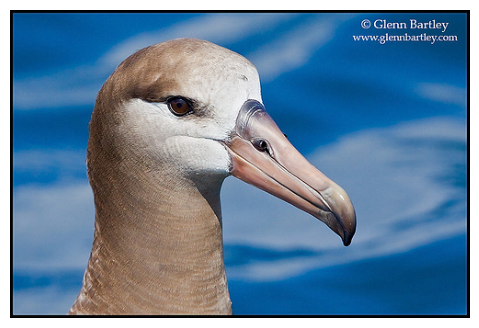

In [61]:
from PIL import Image
import matplotlib.pyplot as plt

# Take one test image
row = test_subset.iloc[0]

image_path = DATASET_PATH / "images" / row["image_path"]
test_image = Image.open(image_path).convert("RGB")

# Predict
predicted_class, predicted_species = predict_bird(test_image)

# Actual species
actual_class = row["class_id"]
actual_species = row["species"]

print("Actual class:", actual_class)
print("Actual species:", actual_species)

print("\nPredicted class:", predicted_class)
print("Predicted species:", predicted_species)

# Display image
plt.figure(figsize=(6, 4))
plt.imshow(test_image)
plt.axis("off")
plt.show()

Actual species: 001.Black_footed_Albatross
Predicted species: 003.Sooty_Albatross


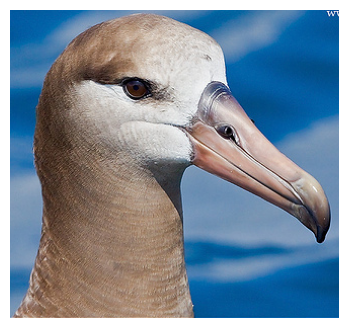

In [63]:
row = test_subset.iloc[0]

image_path = DATASET_PATH / "images" / row["image_path"]
image = Image.open(image_path).convert("RGB")

# Get bounding box
x, y, width, height = bounding_boxes[row["image_id"]]

# Crop bird
cropped = image.crop((
    int(x),
    int(y),
    int(x + width),
    int(y + height)
))

# Predict using the same preprocessing as training
predicted_class, predicted_species = predict_bird(cropped)

print("Actual species:", row["species"])
print("Predicted species:", predicted_species)

plt.figure(figsize=(6, 4))
plt.imshow(cropped)
plt.axis("off")
plt.show()

In [64]:
scores = final_svm.decision_function(
    final_scaler.transform(
        extract_features(cropped).reshape(1, -1)
    )
)

print("Score shape:", scores.shape)

Score shape: (1, 200)


In [65]:
# Get scores for all 200 classes
scores = final_svm.decision_function(
    final_scaler.transform(
        extract_features(cropped).reshape(1, -1)
    )
)[0]

# Get indices of top 5 scores
top5_indices = np.argsort(scores)[-5:][::-1]

print("Top 5 predictions:\n")

for rank, index in enumerate(top5_indices, start=1):
    class_id = final_svm.classes_[index]
    species = classes[class_id]
    score = scores[index]

    print(f"{rank}. {species} | Score: {score:.4f}")

Top 5 predictions:

1. 087.Mallard | Score: 198.3312
2. 003.Sooty_Albatross | Score: 198.3308
3. 102.Western_Wood_Pewee | Score: 191.3294
4. 008.Rhinoceros_Auklet | Score: 190.3294
5. 168.Kentucky_Warbler | Score: 190.3294


In [67]:
!pip install opencv-python

   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 1.3 MB/s eta 0:00:35
   ---------------------------------------- 0.5/44.0 MB 1.3 MB/s eta 0:00:35
    --------------------------------------- 0.8/44.0 MB 738.5 kB/s eta 0:00:59
    --------------------------------------- 0.8/44.0 MB 738.5 kB/s eta 0:00:59
    --------------------------------------- 0.8/44.0 MB 738.5 kB/s eta 0:00:59
    --------------------------------------- 1.0/44.0 MB 664.1 kB/s eta 0:01:05
   - -------------------------------------- 1.3/44.0 MB 670.5 kB/s eta 0:01:04
   - -------------------------------------- 1.3/44.0 MB 670.5 kB/s eta 0:01:04
   - -------------------------------------- 1.6/44.0 MB 714.4 kB/s eta 0:01:00
   - -------------------------------------- 1.8/44.0 MB 736.4 kB/s eta 0:00:58
   -

In [68]:
import cv2
import numpy as np

# Take one cropped training image
row = train_subset_20.iloc[0]

image_path = DATASET_PATH / "images" / row["image_path"]
image = Image.open(image_path).convert("RGB")

x, y, width, height = bounding_boxes[row["image_id"]]

cropped = image.crop((
    int(x),
    int(y),
    int(x + width),
    int(y + height)
))

cropped = cropped.resize((128, 128))

# Convert RGB → HSV
rgb_array = np.array(cropped)
hsv_array = cv2.cvtColor(rgb_array, cv2.COLOR_RGB2HSV)

print("RGB shape:", rgb_array.shape)
print("HSV shape:", hsv_array.shape)
print("HSV minimum:", hsv_array.min(axis=(0, 1)))
print("HSV maximum:", hsv_array.max(axis=(0, 1)))

RGB shape: (128, 128, 3)
HSV shape: (128, 128, 3)
HSV minimum: [0 0 0]
HSV maximum: [179 255 255]


In [69]:
def extract_spatial_hsv_features(image):
    # Resize image
    image = image.convert("RGB")
    image = image.resize((128, 128))

    # Convert PIL image to NumPy
    img_array = np.array(image)

    # Convert RGB → HSV using OpenCV
    hsv = cv2.cvtColor(img_array, cv2.COLOR_RGB2HSV)

    features = []

    # Divide image into 4 × 4 grid
    for i in range(4):
        for j in range(4):

            region = hsv[
                i*32:(i+1)*32,
                j*32:(j+1)*32
            ]

            # Hue histogram
            h_hist, _ = np.histogram(
                region[:, :, 0],
                bins=16,
                range=(0, 180)
            )
            h_hist = h_hist / h_hist.sum()

            # Saturation histogram
            s_hist, _ = np.histogram(
                region[:, :, 1],
                bins=8,
                range=(0, 256)
            )
            s_hist = s_hist / s_hist.sum()

            # Value histogram
            v_hist, _ = np.histogram(
                region[:, :, 2],
                bins=8,
                range=(0, 256)
            )
            v_hist = v_hist / v_hist.sum()

            features.extend(h_hist)
            features.extend(s_hist)
            features.extend(v_hist)

    return np.array(features)

In [72]:
test_image = Image.open(
    DATASET_PATH / "images" / images[1]
)

hsv_features = extract_spatial_hsv_features(test_image)

print("HSV feature shape:", hsv_features.shape)

HSV feature shape: (512,)


In [71]:
hsv_features = extract_spatial_hsv_features(test_image)

print("HSV feature shape:", hsv_features.shape)

HSV feature shape: (512,)


In [73]:
def extract_hsv_hog_features(image):
    image = image.convert("RGB")
    image = image.resize((128, 128))

    img_array = np.array(image)

    # ---------- HSV FEATURES ----------
    hsv = cv2.cvtColor(img_array, cv2.COLOR_RGB2HSV)

    hsv_features = []

    for i in range(4):
        for j in range(4):

            region = hsv[
                i*32:(i+1)*32,
                j*32:(j+1)*32
            ]

            # Hue
            h_hist, _ = np.histogram(
                region[:, :, 0],
                bins=16,
                range=(0, 180)
            )
            h_hist = h_hist / h_hist.sum()

            # Saturation
            s_hist, _ = np.histogram(
                region[:, :, 1],
                bins=8,
                range=(0, 256)
            )
            s_hist = s_hist / s_hist.sum()

            # Value
            v_hist, _ = np.histogram(
                region[:, :, 2],
                bins=8,
                range=(0, 256)
            )
            v_hist = v_hist / v_hist.sum()

            hsv_features.extend(h_hist)
            hsv_features.extend(s_hist)
            hsv_features.extend(v_hist)

    # ---------- HOG FEATURES ----------
    gray_image = np.array(image.convert("L"))

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )

    # ---------- COMBINE ----------
    features = np.concatenate([
        hsv_features,
        hog_features
    ])

    return features

In [74]:
combined_features = extract_hsv_hog_features(test_image)

print("Combined feature shape:", combined_features.shape)

Combined feature shape: (2276,)


In [75]:
X_train_hsv_hog = []

for idx, row in train_subset_20.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_hsv_hog_features(image)

    X_train_hsv_hog.append(features)

X_train_hsv_hog = np.array(X_train_hsv_hog)

print("Training feature shape:", X_train_hsv_hog.shape)

Training feature shape: (4000, 2276)


In [77]:
X_test_hsv_hog = []

for idx, row in test_subset.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_hsv_hog_features(image)

    X_test_hsv_hog.append(features)

X_test_hsv_hog = np.array(X_test_hsv_hog)

print("Test feature shape:", X_test_hsv_hog.shape)

Test feature shape: (400, 2276)


In [79]:
scaler_hsv_hog = StandardScaler()

X_train_hsv_hog_scaled = scaler_hsv_hog.fit_transform(
    X_train_hsv_hog
)

X_test_hsv_hog_scaled = scaler_hsv_hog.transform(
    X_test_hsv_hog
)

print("Scaled training shape:", X_train_hsv_hog_scaled.shape)
print("Scaled test shape:", X_test_hsv_hog_scaled.shape)

Scaled training shape: (4000, 2276)
Scaled test shape: (400, 2276)


In [80]:
hsv_hog_svm = SVC(
    kernel="linear",
    C=1
)

hsv_hog_svm.fit(
    X_train_hsv_hog_scaled,
    y_train_20
)

y_pred_hsv_hog = hsv_hog_svm.predict(
    X_test_hsv_hog_scaled
)

In [81]:
hsv_hog_accuracy = accuracy_score(
    y_test,
    y_pred_hsv_hog
)

print("Spatial HSV + HOG Accuracy:", hsv_hog_accuracy)
print("Accuracy percentage:", hsv_hog_accuracy * 100)

Spatial HSV + HOG Accuracy: 0.0625
Accuracy percentage: 6.25


In [82]:
from scipy.stats import skew

def extract_color_moment_hog_features(image):
    image = image.convert("RGB")
    image = image.resize((128, 128))

    img_array = np.array(image).astype(np.float32)

    color_features = []

    # 4 × 4 spatial grid
    for i in range(4):
        for j in range(4):

            region = img_array[
                i*32:(i+1)*32,
                j*32:(j+1)*32
            ]

            # RGB channels
            for channel in range(3):
                channel_data = region[:, :, channel].flatten()

                mean = np.mean(channel_data)
                std = np.std(channel_data)
                skewness = skew(channel_data)

                color_features.extend([
                    mean,
                    std,
                    skewness
                ])

    # HOG
    gray_image = np.array(image.convert("L"))

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )

    # Combine
    features = np.concatenate([
        color_features,
        hog_features
    ])

    return features

In [83]:
moment_features = extract_color_moment_hog_features(test_image)

print("Feature shape:", moment_features.shape)

Feature shape: (1908,)


In [84]:
X_train_moments = []

for idx, row in train_subset_20.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_color_moment_hog_features(image)

    X_train_moments.append(features)

X_train_moments = np.array(X_train_moments)

print("Training feature shape:", X_train_moments.shape)

C:\Users\Vinay\AppData\Local\Temp\ipykernel_1844\3895940639.py:26: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  skewness = skew(channel_data)


Training feature shape: (4000, 1908)


In [85]:
def extract_color_moment_hog_features(image):
    image = image.convert("RGB")
    image = image.resize((128, 128))

    img_array = np.array(image).astype(np.float32)

    color_features = []

    # 4 × 4 spatial grid
    for i in range(4):
        for j in range(4):

            region = img_array[
                i*32:(i+1)*32,
                j*32:(j+1)*32
            ]

            for channel in range(3):
                channel_data = region[:, :, channel].flatten()

                mean = np.mean(channel_data)
                std = np.std(channel_data)

                # Avoid unreliable skewness when values are almost identical
                if std < 1e-6:
                    skewness = 0.0
                else:
                    skewness = skew(channel_data)

                color_features.extend([
                    mean,
                    std,
                    skewness
                ])

    # HOG
    gray_image = np.array(image.convert("L"))

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )

    features = np.concatenate([
        color_features,
        hog_features
    ])

    return features

In [86]:
X_train_moments = []

for idx, row in train_subset_20.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_color_moment_hog_features(image)

    X_train_moments.append(features)

X_train_moments = np.array(X_train_moments)

print("Training feature shape:", X_train_moments.shape)

Training feature shape: (4000, 1908)


In [87]:
X_test_moments = []

for idx, row in test_subset.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_color_moment_hog_features(image)

    X_test_moments.append(features)

X_test_moments = np.array(X_test_moments)

print("Test feature shape:", X_test_moments.shape)

Test feature shape: (400, 1908)


In [88]:
scaler_moments = StandardScaler()

X_train_moments_scaled = scaler_moments.fit_transform(
    X_train_moments
)

X_test_moments_scaled = scaler_moments.transform(
    X_test_moments
)

print("Scaled training shape:", X_train_moments_scaled.shape)
print("Scaled test shape:", X_test_moments_scaled.shape)

Scaled training shape: (4000, 1908)
Scaled test shape: (400, 1908)


In [89]:
moments_svm = SVC(
    kernel="linear",
    C=1
)

moments_svm.fit(
    X_train_moments_scaled,
    y_train_20
)

y_pred_moments = moments_svm.predict(
    X_test_moments_scaled
)

In [90]:
moments_accuracy = accuracy_score(
    y_test,
    y_pred_moments
)

print("Color Moments + HOG Accuracy:", moments_accuracy)
print("Accuracy percentage:", moments_accuracy * 100)

Color Moments + HOG Accuracy: 0.065
Accuracy percentage: 6.5


In [91]:
from skimage.filters import gabor

In [92]:
gray_test = np.array(test_image.convert("L").resize((128, 128)))

real, imag = gabor(
    gray_test,
    frequency=0.2,
    theta=0
)

print("Gabor real shape:", real.shape)
print("Gabor imag shape:", imag.shape)

Gabor real shape: (128, 128)
Gabor imag shape: (128, 128)


In [95]:
def extract_best_handcrafted_features(image):
    image = image.convert("RGB")
    image = image.resize((128, 128))

    img_array = np.array(image)

    # ==========================================
    # 1. RGB COLOR FEATURES
    # ==========================================

    color_features = []

    for channel in range(3):
        histogram, _ = np.histogram(
            img_array[:, :, channel],
            bins=32,
            range=(0, 256)
        )

        histogram = histogram / histogram.sum()
        color_features.extend(histogram)

    # ==========================================
    # 2. GABOR TEXTURE FEATURES
    # ==========================================

    gray_image = np.array(
        image.convert("L"),
        dtype=np.float64
    )

    gabor_features = []

    orientations = [
        0,
        np.pi / 4,
        np.pi / 2,
        3 * np.pi / 4
    ]

    for theta in orientations:

        real, imag = gabor(
            gray_image,
            frequency=0.2,
            theta=theta
        )

        # Convert to float64
        real = np.asarray(real, dtype=np.float64)
        imag = np.asarray(imag, dtype=np.float64)

        # Calculate magnitude safely
        magnitude = np.hypot(real, imag)

        # Normalize Gabor response
        max_value = np.max(magnitude)

        if max_value > 0:
            magnitude = magnitude / max_value

        # Now calculate statistics
        gabor_features.append(float(np.mean(magnitude)))
        gabor_features.append(float(np.std(magnitude)))

    # ==========================================
    # 3. HOG FEATURES
    # ==========================================

    hog_features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(16, 16),
        cells_per_block=(2, 2)
    )

    # ==========================================
    # 4. COMBINE
    # ==========================================

    features = np.concatenate([
        np.asarray(color_features, dtype=np.float64),
        np.asarray(gabor_features, dtype=np.float64),
        np.asarray(hog_features, dtype=np.float64)
    ])

    return features

In [96]:
best_features = extract_best_handcrafted_features(test_image)

print("Feature shape:", best_features.shape)
print("Contains NaN:", np.isnan(best_features).any())
print("Contains Inf:", np.isinf(best_features).any())
print("Maximum:", np.max(best_features))
print("Minimum:", np.min(best_features))

Feature shape: (1868,)
Contains NaN: False
Contains Inf: False
Maximum: 0.4324663868429037
Minimum: 0.0


In [97]:
X_train_best = []

for idx, row in train_subset_20.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_best_handcrafted_features(image)

    X_train_best.append(features)

X_train_best = np.array(X_train_best)

print("Training feature shape:", X_train_best.shape)
print("Contains NaN:", np.isnan(X_train_best).any())
print("Contains Inf:", np.isinf(X_train_best).any())

Training feature shape: (4000, 1868)
Contains NaN: False
Contains Inf: False


In [98]:
X_test_best = []

for idx, row in test_subset.iterrows():
    image_path = DATASET_PATH / "images" / row["image_path"]

    image = Image.open(image_path)

    features = extract_best_handcrafted_features(image)

    X_test_best.append(features)

X_test_best = np.array(X_test_best)

print("Test feature shape:", X_test_best.shape)
print("Contains NaN:", np.isnan(X_test_best).any())
print("Contains Inf:", np.isinf(X_test_best).any())

Test feature shape: (400, 1868)
Contains NaN: False
Contains Inf: False


In [99]:
scaler_best = StandardScaler()

X_train_best_scaled = scaler_best.fit_transform(
    X_train_best
)

X_test_best_scaled = scaler_best.transform(
    X_test_best
)

print("Scaled training:", X_train_best_scaled.shape)
print("Scaled test:", X_test_best_scaled.shape)

Scaled training: (4000, 1868)
Scaled test: (400, 1868)


In [100]:
best_svm = SVC(
    kernel="linear",
    C=1
)

best_svm.fit(
    X_train_best_scaled,
    y_train_20
)

y_pred_best = best_svm.predict(
    X_test_best_scaled
)

In [101]:
best_accuracy = accuracy_score(
    y_test,
    y_pred_best
)

print("Gabor + HOG + RGB Accuracy:", best_accuracy)
print("Accuracy percentage:", best_accuracy * 100)

Gabor + HOG + RGB Accuracy: 0.06
Accuracy percentage: 6.0
